# One-step displacement AE

Low-T node- and stiffness-optimized networks only. The encoder sees the current displacement from the reference graph, while the decoder predicts the **next stored-frame increment**, (x_{t+1}-x_t). One versus twenty training networks per source; held-out IDs 40–119. These are teacher-forced one-step predictions, not autonomous rollouts.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / 'notebooks').exists():
    if ROOT.parent == ROOT:
        raise RuntimeError('Run this notebook from inside the repository.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from lss.plotting import apply_editorial_style, PAPER_COLORS, style_axes
apply_editorial_style('light')

BASE = ROOT / 'notebooks/results/mini_temperature200_one_step_ae'
SOURCES = ('node_low', 'stiffness_low')
SOURCE_NAMES = {'node_low': 'Node optimized', 'stiffness_low': 'Stiffness optimized'}
SOURCE_COLORS = {'node_low': PAPER_COLORS['blue'], 'stiffness_low': PAPER_COLORS['red']}
SEEDS = (123, 456, 786)
COUNTS = (1, 20)
DISPLAY_SEED = 456

initial = pd.concat([pd.read_csv(BASE / f'count{count}_seed{seed}/initial_latents.csv')
                     for count in COUNTS for seed in SEEDS], ignore_index=True)
paths = pd.concat([pd.read_csv(BASE / f'count{count}_seed{DISPLAY_SEED}/trajectory_latents_20_ids.csv')
                   for count in COUNTS], ignore_index=True)
quality = pd.concat([pd.read_csv(BASE / f'count{count}_seed{seed}/summary.csv')
                     for count in COUNTS for seed in SEEDS], ignore_index=True)
assert set(initial.source) == set(SOURCES) and set(paths.source) == set(SOURCES)
assert all(len(g) == 80 for _, g in initial.groupby(['count', 'seed', 'source']))
assert all(len(g) == 20 * 500 for _, g in paths.groupby(['count', 'source']))
assert all((quality.valid == 80) & (quality.total == 80))


## Initial latent and final p-ratio

Only initial z1 is shown. It is the stronger coordinate in all four display-seed panels; latent axes can change across independently trained seeds. Each correlation uses 80 unseen networks.


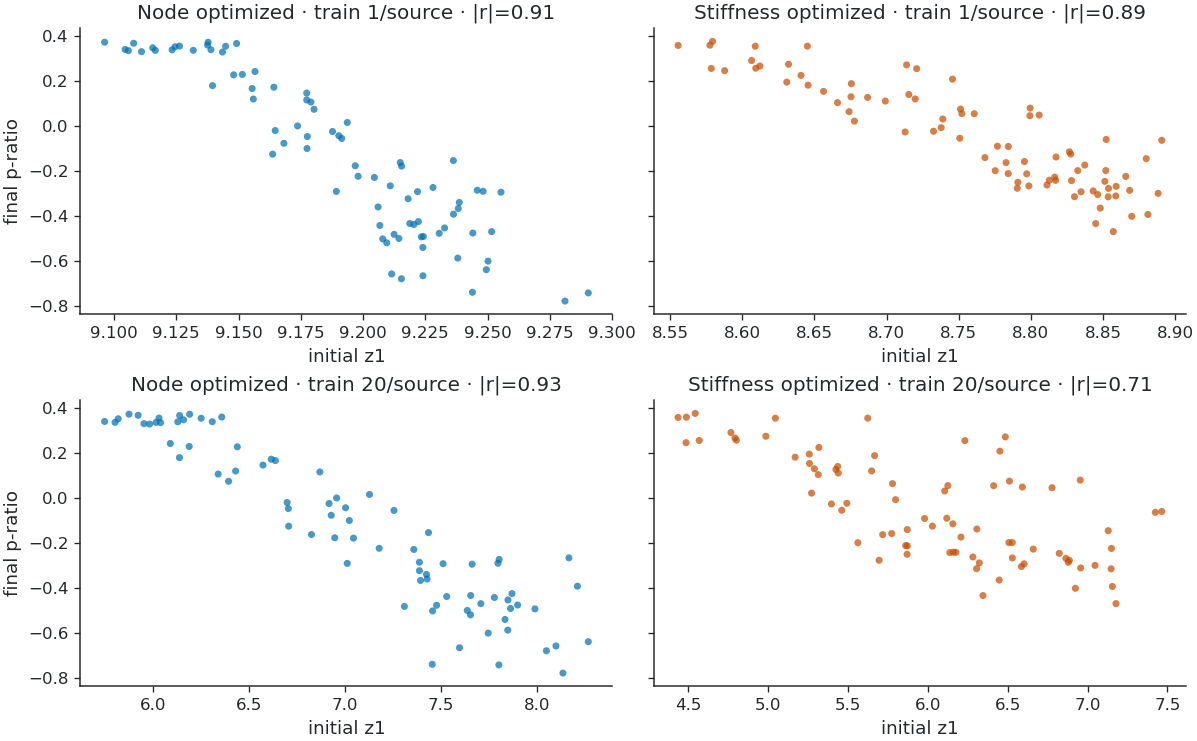

seed                                            123    456    786
training networks/source source                                  
1                        Node optimized       0.739  0.911  0.304
                         Stiffness optimized  0.834  0.893  0.793
20                       Node optimized       0.902  0.933  0.919
                         Stiffness optimized  0.669  0.705  0.120

In [2]:
rows = []
for (count, seed, source), group in initial.groupby(['count', 'seed', 'source']):
    rows.append({'training networks/source': count, 'seed': seed,
                 'source': SOURCE_NAMES[source],
                 '|Pearson r|': abs(group.z1.corr(group.final_endpoint_p_ratio)),
                 'valid/total': f'{len(group)}/80'})
initial_correlations = pd.DataFrame(rows)
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2), constrained_layout=True,
                         sharey=True)
for row, count in enumerate(COUNTS):
    for col, source in enumerate(SOURCES):
        group = initial.query('count == @count and seed == @DISPLAY_SEED and source == @source')
        ax = axes[row, col]
        ax.scatter(group.z1, group.final_endpoint_p_ratio, s=18, alpha=.72,
                   color=SOURCE_COLORS[source], edgecolor='none')
        r = group.z1.corr(group.final_endpoint_p_ratio)
        ax.set_title(f'{SOURCE_NAMES[source]} · train {count}/source · |r|={abs(r):.2f}')
        style_axes(ax, xlabel='initial z1', ylabel='final p-ratio' if col == 0 else '')
plt.show()
display(initial_correlations.pivot_table(
    index=['training networks/source', 'source'], columns='seed',
    values='|Pearson r|').round(3))


## Same held-out trajectories

The same ten fixed held-out networks per source appear for both encoders. Paths show true frames 0–100 in each model's **raw** z0–z1 space; colour is final p-ratio. No rotation, alignment or rescaling is applied.


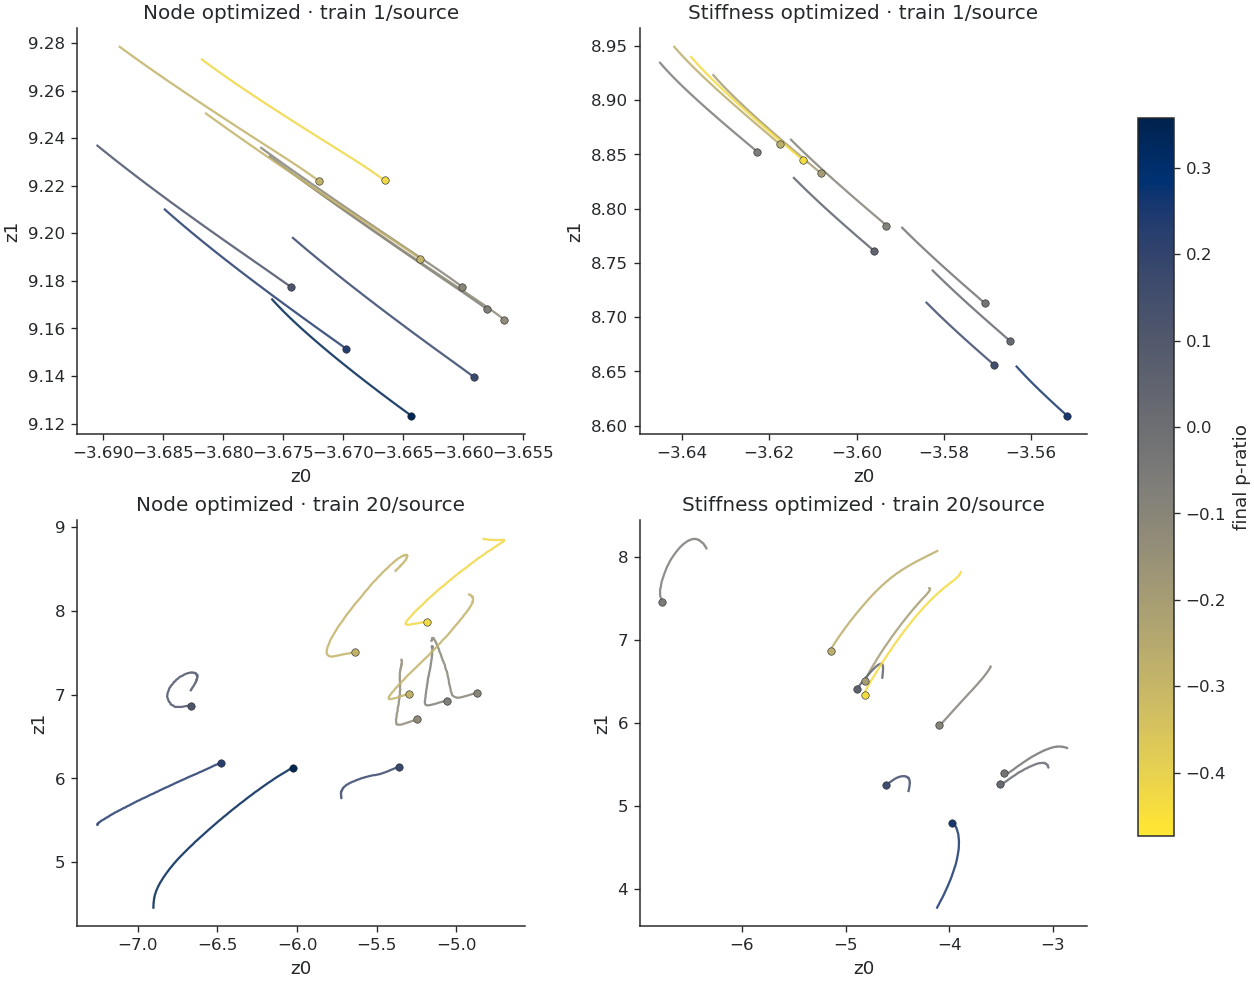

In [3]:
display_initial = initial.query('count == 20 and seed == @DISPLAY_SEED and trajectory_id < 60')
selected_ids = {source: list(range(40, 60, 2)) for source in SOURCES}
values = display_initial.final_endpoint_p_ratio
norm = Normalize(vmin=values.quantile(.02), vmax=values.quantile(.98))
cmap = plt.get_cmap('cividis_r')
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.2), constrained_layout=True)
for row, count in enumerate(COUNTS):
    for col, source in enumerate(SOURCES):
        ax = axes[row, col]
        for trajectory_id in selected_ids[source]:
            path = paths.query('count == @count and source == @source and trajectory_id == @trajectory_id and frame <= 100').sort_values('frame')
            p_ratio = float(display_initial.query('source == @source and trajectory_id == @trajectory_id').final_endpoint_p_ratio.iloc[0])
            color = cmap(norm(p_ratio))
            ax.plot(path.z0, path.z1, color=color, lw=1.35, alpha=.86)
            ax.scatter(path.z0.iloc[0], path.z1.iloc[0], s=20, color=color,
                       edgecolor=PAPER_COLORS['ink'], linewidth=.35, zorder=3)
        ax.set_title(f'{SOURCE_NAMES[source]} · train {count}/source')
        style_axes(ax, xlabel='z0', ylabel='z1')
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes,
             label='final p-ratio', shrink=.8)
plt.show()


## One versus twenty on shared axes

The same paths are overlaid in one raw z0–z1 plot: blue is trained on one network per source, red on twenty; solid is node-optimized, dashed is stiffness-optimized. The right panel zooms the one-network paths. Because the two encoders learned independent coordinates, compare path shapes **within** each model, not absolute locations between models.


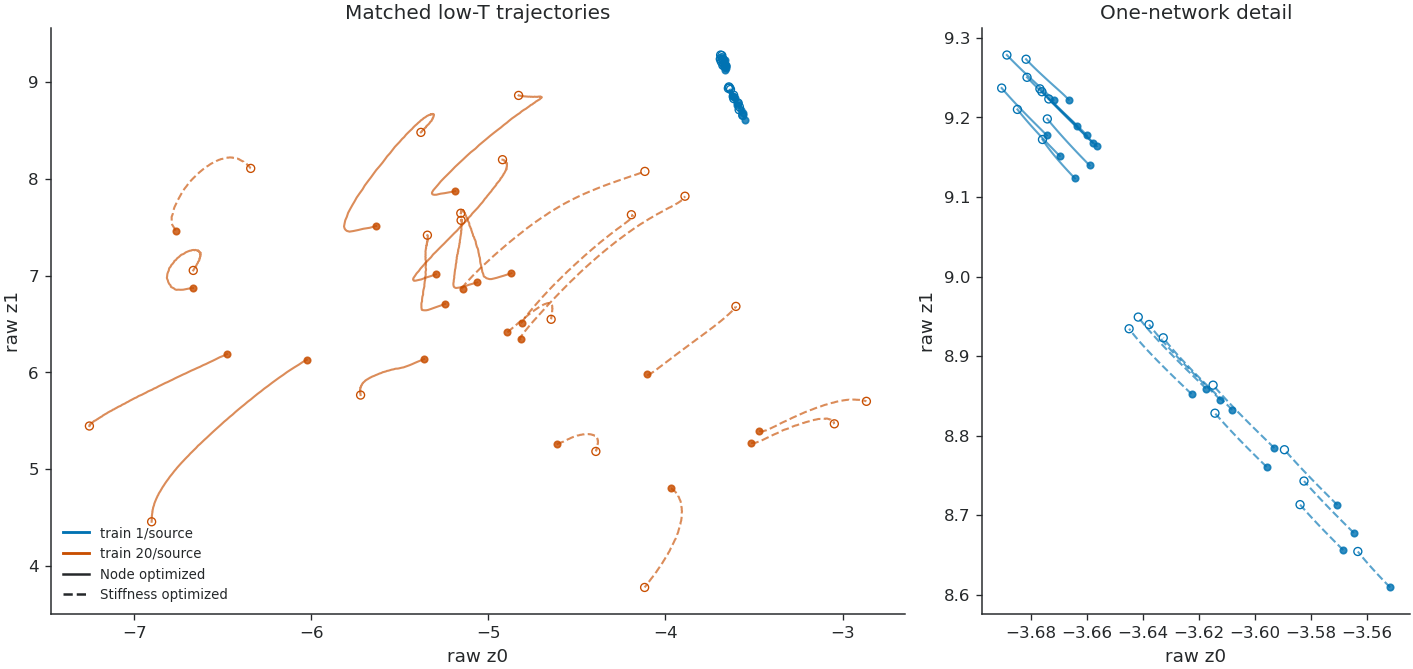

In [4]:
from matplotlib.lines import Line2D

MODEL_COLORS = {1: PAPER_COLORS['blue'], 20: PAPER_COLORS['red']}
SOURCE_STYLES = {'node_low': '-', 'stiffness_low': '--'}
fig, (ax, zoom_ax) = plt.subplots(1, 2, figsize=(11.8, 5.6),
                                  gridspec_kw={'width_ratios': [3.0, 1.5]},
                                  constrained_layout=True)
for source in SOURCES:
    for trajectory_id in selected_ids[source]:
        for count in COUNTS:
            path = paths.query('count == @count and source == @source and trajectory_id == @trajectory_id and frame <= 100').sort_values('frame')
            color = MODEL_COLORS[count]
            for target_ax in ([ax, zoom_ax] if count == 1 else [ax]):
                target_ax.plot(path.z0, path.z1, color=color, ls=SOURCE_STYLES[source],
                               lw=1.25, alpha=.65)
                target_ax.scatter(path.z0.iloc[0], path.z1.iloc[0], color=color, s=15,
                                  alpha=.8, zorder=3)
                target_ax.scatter(path.z0.iloc[-1], path.z1.iloc[-1], facecolors='none',
                                  edgecolors=color, s=23, linewidth=.8, zorder=3)
ax.set_title('Matched low-T trajectories')
zoom_ax.set_title('One-network detail')
for target_ax in (ax, zoom_ax):
    style_axes(target_ax, xlabel='raw z0', ylabel='raw z1')
handles = [Line2D([0], [0], color=MODEL_COLORS[count], lw=1.7,
                  label=f'train {count}/source') for count in COUNTS]
handles += [Line2D([0], [0], color=PAPER_COLORS['ink'], ls=SOURCE_STYLES[source],
                   lw=1.5, label=SOURCE_NAMES[source]) for source in SOURCES]
ax.legend(handles=handles, fontsize=8, loc='lower left', frameon=False)
plt.show()


## Motion slope and final response

For each held-out trajectory, fit a straight slope of z0 or z1 against frame over frames 0–20 or 0–100. The plots use 20 matched held-out networks per source (display seed 456). This is an **across-network** association between motion slope and final p-ratio, not a framewise latent-to-deformation correlation.


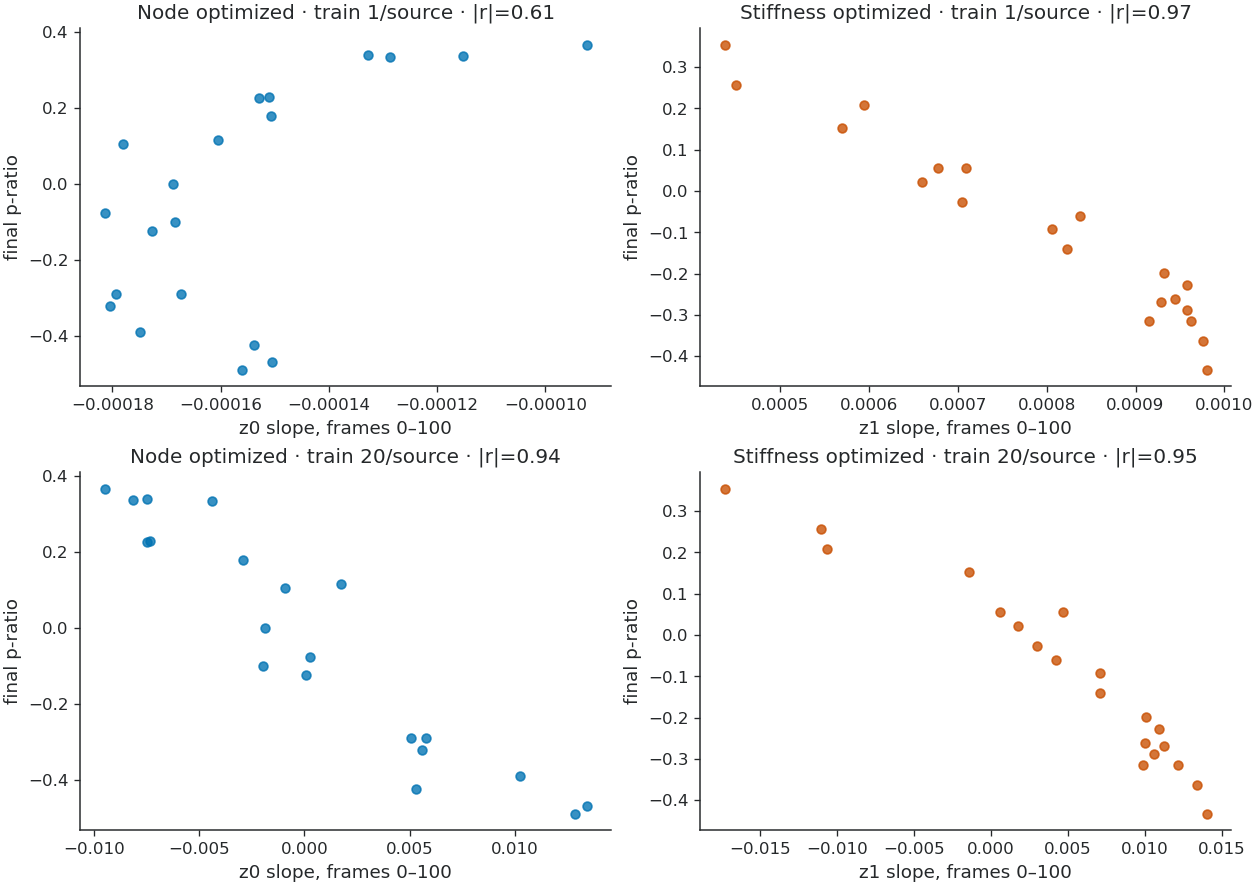

coordinate                     z0     z1
count source        frames              
1     node_low      0–100   0.609  0.047
                    0–20    0.505  0.064
      stiffness_low 0–100   0.966  0.972
                    0–20    0.917  0.928
20    node_low      0–100   0.940  0.919
                    0–20    0.905  0.939
      stiffness_low 0–100   0.852  0.953
                    0–20    0.915  0.918

In [5]:
slope_rows = []
for (count, source, trajectory_id), path in paths.groupby(['count', 'source', 'trajectory_id']):
    final_p = float(initial.query('count == @count and seed == @DISPLAY_SEED and source == @source and trajectory_id == @trajectory_id').final_endpoint_p_ratio.iloc[0])
    for stop in (20, 100):
        segment = path[path.frame.le(stop)].sort_values('frame')
        for latent in ('z0', 'z1'):
            slope = np.polyfit(segment.frame.to_numpy(), segment[latent].to_numpy(), 1)[0]
            slope_rows.append({'count': count, 'source': source, 'trajectory_id': trajectory_id,
                               'frames': f'0–{stop}', 'coordinate': latent,
                               'slope per frame': slope, 'final p-ratio': final_p})
slopes = pd.DataFrame(slope_rows)
slope_correlations = (slopes.groupby(['count', 'source', 'frames', 'coordinate'])
                      .apply(lambda g: abs(g['slope per frame'].corr(g['final p-ratio'])),
                             include_groups=False).rename('|Pearson r|').reset_index())
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.4), constrained_layout=True)
for row, count in enumerate(COUNTS):
    for col, source in enumerate(SOURCES):
        ax = axes[row, col]
        options = slope_correlations.query('count == @count and source == @source and frames == "0–100"')
        coordinate = options.loc[options['|Pearson r|'].idxmax(), 'coordinate']
        group = slopes.query('count == @count and source == @source and frames == "0–100" and coordinate == @coordinate')
        ax.scatter(group['slope per frame'], group['final p-ratio'], color=SOURCE_COLORS[source],
                   s=28, alpha=.78)
        r = group['slope per frame'].corr(group['final p-ratio'])
        ax.set_title(f'{SOURCE_NAMES[source]} · train {count}/source · |r|={abs(r):.2f}')
        style_axes(ax, xlabel=f'{coordinate} slope, frames 0–100', ylabel='final p-ratio')
plt.show()
display(slope_correlations.pivot_table(index=['count', 'source', 'frames'],
                                       columns='coordinate', values='|Pearson r|').round(3))


## One-step prediction check

The decoder predicts an increment and the true current position is added before measuring p-ratio. Thus the late-frame p-ratio R² below is **not rollout R²**: the true trajectory is supplied again at every step. Early-frame accuracy is more informative for this one-step task. Values are seed mean ± SD on held-out-development IDs 40–119, with 80/80 valid per source and seed.


In [6]:
check = quality[quality.target_frame.isin([1, 5, 20, 100])].copy()
check['source'] = check.source.map(SOURCE_NAMES)
check['training networks/source'] = check['count']
performance = (check.groupby(['training networks/source', 'source', 'target_frame'])
               .agg(p_ratio_R2_mean=('p_ratio_r2', 'mean'),
                    p_ratio_R2_SD=('p_ratio_r2', 'std'),
                    increment_MSE_mean=('normalized_step_mse', 'mean'),
                    increment_MSE_SD=('normalized_step_mse', 'std'),
                    seeds=('seed', 'nunique'), valid=('valid', 'sum'), total=('total', 'sum'))
               .reset_index())
display(performance.round(3))


,training networks/source,source,target_frame,p_ratio_R2_mean,p_ratio_R2_SD,increment_MSE_mean,increment_MSE_SD,seeds,valid,total
0,1,Node optimized,1,-244.307,8.694,1.741,0.068,3,240,240
1,1,Node optimized,5,-2.869,0.472,1.194,0.049,3,240,240
2,1,Node optimized,20,0.993,0.001,0.881,0.017,3,240,240
3,1,Node optimized,100,1.000,0.000,1.244,0.027,3,240,240
4,1,Stiffness optimized,1,-69.225,8.685,0.836,0.139,3,240,240
5,1,Stiffness optimized,5,-0.022,0.288,0.544,0.111,3,240,240
6,1,Stiffness optimized,20,0.993,0.002,0.471,0.064,3,240,240
7,1,Stiffness optimized,100,1.000,0.000,0.629,0.050,3,240,240
8,20,Node optimized,1,-94.467,36.530,0.408,0.146,3,240,240
9,20,Node optimized,5,0.070,0.570,0.191,0.070,3,240,240
